In [ ]:
Advertising Dataset – Sales Prediction

In [ ]:
Business Scenario
A consumer goods company uses TV, Radio, and Newspaper advertising. The goal is to understand how these channels influence sales and predict sales for a future advertising budget.

Features: TV, Radio, Newspaper
Target: Sales
Model: Multiple Linear Regression

In [ ]:
1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
2. Load the Dataset

In [5]:
df = pd.read_csv('advertising.csv')

# Handle datasets that contain an extra unnamed index column
df = df.loc[:, ~df.columns.astype(str).str.startswith('Unnamed')]

print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [ ]:
3. Examine Columns and Basic Information

In [6]:
print('Columns:', list(df.columns))
print('\nData types and missing values:')
display(pd.DataFrame({'Data Type': df.dtypes, 'Missing Values': df.isnull().sum()}))
print('\nSummary statistics:')
display(df.describe())

Columns: ['TV', 'Radio', 'Newspaper', 'Sales']

Data types and missing values:


,Data Type,Missing Values
TV,float64,0
Radio,float64,0
Newspaper,float64,0
Sales,float64,0



Summary statistics:


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [ ]:
4. Select Features and Target

In [7]:
features = ['TV', 'Radio', 'Newspaper']
target = 'Sales'

X = df[features]
y = df[target]

print('Input features:', features)
print('Target:', target)

Input features: ['TV', 'Radio', 'Newspaper']
Target: Sales


In [ ]:
5. Split Data into Training and Testing Sets

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print('Training samples:', len(X_train))
print('Testing samples:', len(X_test))

Training samples: 160
Testing samples: 40


In [ ]:
6. Train the Multiple Linear Regression Model

In [9]:
model = LinearRegression()
model.fit(X_train, y_train)

print('Model trained successfully.')
print('Intercept:', round(model.intercept_, 4))

coefficients = pd.DataFrame({
    'Advertising Medium': features,
    'Coefficient': model.coef_
})
display(coefficients)

Model trained successfully.
Intercept: 4.7141


,Advertising Medium,Coefficient
0,TV,0.054509
1,Radio,0.100945
2,Newspaper,0.004337


In [ ]:
Model Equation
The model follows the form:

Sales = Intercept + (TV coefficient × TV) + (Radio coefficient × Radio) + (Newspaper coefficient × Newspaper)

In [10]:
print(
    f'Sales = {model.intercept_:.4f} '
    f'+ ({model.coef_[0]:.4f} × TV) '
    f'+ ({model.coef_[1]:.4f} × Radio) '
    f'+ ({model.coef_[2]:.4f} × Newspaper)'
)

Sales = 4.7141 + (0.0545 × TV) + (0.1009 × Radio) + (0.0043 × Newspaper)


In [ ]:
7. Predict Sales for Unseen Test Data

In [11]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})
comparison['Error'] = comparison['Actual Sales'] - comparison['Predicted Sales']
display(comparison.head(10))

,Actual Sales,Predicted Sales,Error
0,16.9,17.034772,-0.134772
1,22.4,20.409740,1.990260
2,21.4,23.723989,-2.323989
3,7.3,9.272785,-1.972785
4,24.7,21.682719,3.017281
5,12.6,12.569402,0.030598
6,22.3,21.081195,1.218805
7,8.4,8.690350,-0.290350
8,16.5,17.237013,-0.737013
9,16.1,16.666575,-0.566575


In [ ]:
8. Evaluate Prediction Error

In [12]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f'Mean Absolute Error (MAE): {mae:.4f}')
print(f'Root Mean Squared Error (RMSE): {rmse:.4f}')
print(f'R-squared (R²): {r2:.4f}')

Mean Absolute Error (MAE): 1.2748
Root Mean Squared Error (RMSE): 1.7052
R-squared (R²): 0.9059


In [ ]:
9. Predict Sales for the Planned Advertising Budget

In [13]:
future_budget = pd.DataFrame({
    'TV': [150],
    'Radio': [20],
    'Newspaper': [30]
})

future_sales = model.predict(future_budget)[0]
print(f'Predicted sales for TV=150, Radio=20, Newspaper=30: {future_sales:.2f}')

Predicted sales for TV=150, Radio=20, Newspaper=30: 15.04


In [ ]:
10. Interpret the Coefficients

In [14]:
coef_series = pd.Series(model.coef_, index=features)
strongest = coef_series.abs().idxmax()
weakest = coef_series.abs().idxmin()

print('Coefficients:')
for medium, coef in coef_series.items():
    print(f'{medium}: {coef:.4f}')

print(f'\nStrongest impact based on coefficient magnitude: {strongest}')
print(f'Least impact based on coefficient magnitude: {weakest}')

print('\nNote: Coefficients are measured in the dataset\'s original units. For a strictly scale-independent comparison, standardized coefficients can be used.')

Coefficients:
TV: 0.0545
Radio: 0.1009
Newspaper: 0.0043

Strongest impact based on coefficient magnitude: Radio
Least impact based on coefficient magnitude: Newspaper

Note: Coefficients are measured in the dataset's original units. For a strictly scale-independent comparison, standardized coefficients can be used.


In [ ]:
11. Visualize Actual Sales vs Predicted Sales

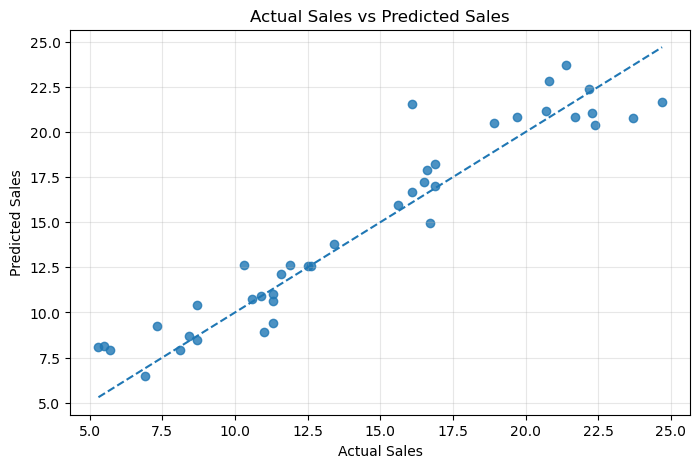

In [15]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.8)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle='--')
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual Sales vs Predicted Sales')
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
13.BUSINESS RECOMMENDATION

In [ ]:
Recommendation: The company should give higher priority to TV advertising, as it shows the strongest positive association with sales in this dataset. Radio advertising should also receive a reasonable budget, while Newspaper advertising can be used selectively depending on the performance of individual campaigns.

In [ ]:
14.TECHNICAL IMPROVEMENT

In [ ]:
Improvement: More advanced machine learning techniques, such as Random Forest Regression and Gradient Boosting, can be explored to improve the model. Applying cross-validation and hyperparameter tuning can further enhance prediction performance and help capture non-linear relationships that a basic linear regression model may not identify.

In [ ]:
15.FINAL CONCLUSION

In [ ]:
Conclusion: Multiple Linear Regression provides a useful approach for predicting Sales using TV, Radio, and Newspaper advertising expenditure. The model can be trained using historical data, evaluated on unseen test data, and then applied to predict sales for a new advertising budget. The model coefficients also provide insight into the relative contribution of each advertising channel to the predicted sales.